# TP Ingénierie des caractéristiques - Titanic

## 1. Chargement

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.feature_selection import chi2, RFE
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.decomposition import PCA
from skrebate import ReliefF

df = pd.read_csv("titanic.csv")
print(df.shape)
print(df.isnull().sum())

(891, 12)
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


## 2. Préparation des données

Suppression des colonnes inutiles

In [ ]:
df = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

Valeurs manquantes

In [ ]:
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
print(df.isnull().sum().sum(), "valeurs manquantes restantes")

0 valeurs manquantes restantes


Transformation logarithmique

skewness Fare avant : 4.79
skewness Fare après : 0.39


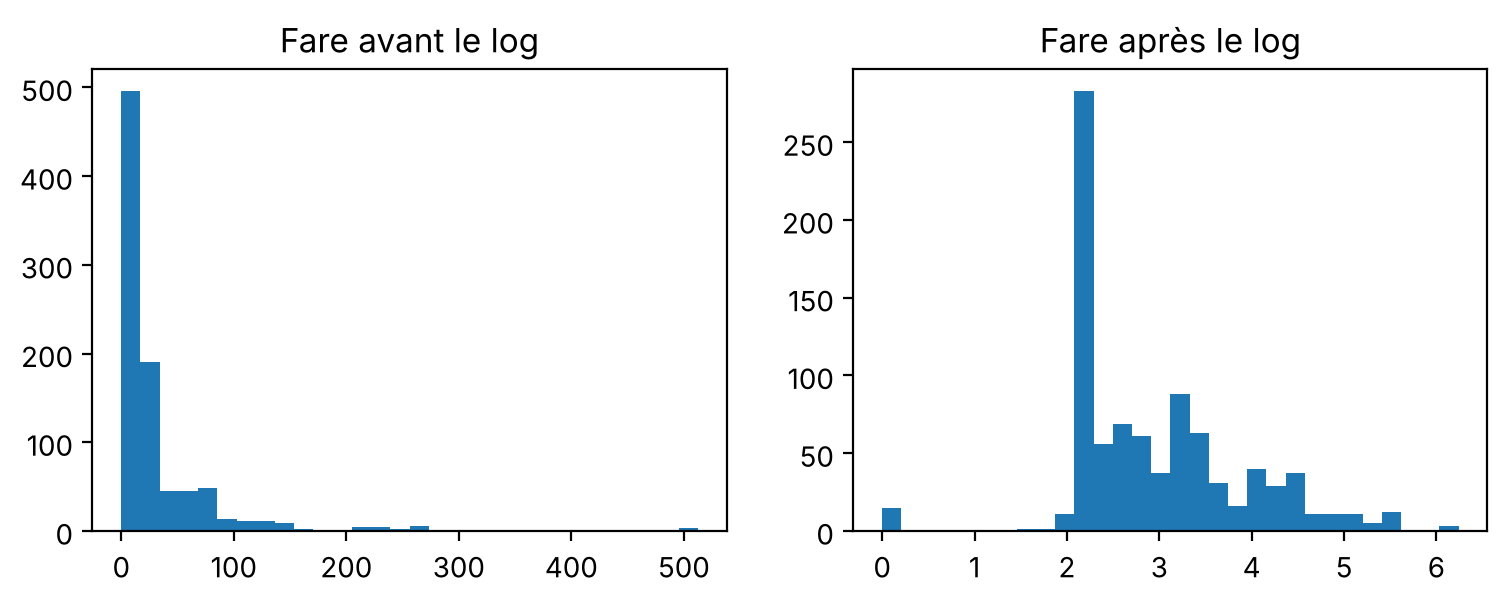

In [ ]:
fare_avant = df["Fare"].copy()
print("skewness Fare avant :", round(df["Fare"].skew(), 2))
df["Fare"] = np.log1p(df["Fare"])
print("skewness Fare après :", round(df["Fare"].skew(), 2))

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].hist(fare_avant, bins=30)
ax[0].set_title("Fare avant le log")
ax[1].hist(df["Fare"], bins=30)
ax[1].set_title("Fare après le log")
plt.show()

Valeurs aberrantes (méthode IQR)

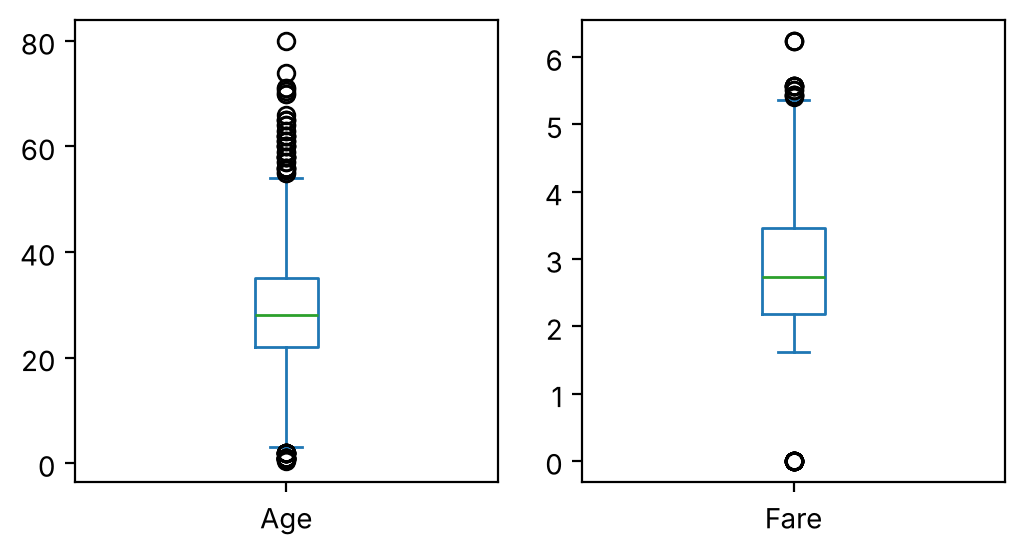

Age : 66 valeurs aberrantes limitées aux bornes
Fare : 31 valeurs aberrantes limitées aux bornes


In [ ]:
df[["Age", "Fare"]].plot(kind="box", subplots=True, figsize=(6, 3))
plt.show()

for col in ["Age", "Fare"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    bas = q1 - 1.5 * iqr
    haut = q3 + 1.5 * iqr
    nb = ((df[col] < bas) | (df[col] > haut)).sum()
    df[col] = df[col].clip(bas, haut)
    print(col, ":", nb, "valeurs aberrantes limitées aux bornes")

Encodage One-Hot

In [ ]:
df = pd.get_dummies(df, columns=["Sex", "Embarked"], drop_first=True, dtype=int)
print(list(df.columns))

['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S']


Mise à l'échelle

In [ ]:
y = df["Survived"]
X = df.drop(columns="Survived")
X = pd.DataFrame(MinMaxScaler().fit_transform(X), columns=X.columns)

Suppression des caractéristiques inutiles (variance faible ou corrélation > 0.9)

In [ ]:
print(X.var().round(3))

corr = X.corr().abs()
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        if corr.iloc[i, j] > 0.9:
            print("corrélées :", corr.columns[i], corr.columns[j])
print("fin de la vérification")

Pclass        0.175
Age           0.054
SibSp         0.019
Parch         0.018
Fare          0.034
Sex_male      0.228
Embarked_Q    0.079
Embarked_S    0.200
dtype: float64
fin de la vérification


## 3. Sélection de caractéristiques

Filtre : Chi2

In [ ]:
scores, pvalues = chi2(X, y)
res = pd.DataFrame({"variable": X.columns, "chi2": scores, "p_value": pvalues})
res = res.sort_values("chi2", ascending=False)
print(res)
sel_chi2 = res["variable"].head(5).tolist()
print("Chi2 :", sel_chi2)

     variable       chi2       p_value
5    Sex_male  92.702447  6.077838e-22
0      Pclass  27.232933  1.803602e-07
4        Fare   6.294426  1.211183e-02
7  Embarked_S   5.489205  1.913424e-02
3       Parch   1.682917  1.945374e-01
1         Age   0.345402  5.567273e-01
2       SibSp   0.322733  5.699697e-01
6  Embarked_Q   0.010847  9.170520e-01
Chi2 : ['Sex_male', 'Pclass', 'Fare', 'Embarked_S', 'Parch']


Filtre : ReliefF

In [ ]:
relief = ReliefF(n_features_to_select=5, n_neighbors=10)
relief.fit(X.values, y.values)
res = pd.DataFrame({"variable": X.columns, "score": relief.feature_importances_})
res = res.sort_values("score", ascending=False)
print(res)
sel_relief = res["variable"].head(5).tolist()
print("ReliefF :", sel_relief)

     variable     score
5    Sex_male  0.159147
1         Age  0.066535
0      Pclass  0.050056
4        Fare  0.041489
2       SibSp  0.036251
3       Parch  0.006622
7  Embarked_S  0.005612
6  Embarked_Q  0.003367
ReliefF : ['Sex_male', 'Age', 'Pclass', 'Fare', 'SibSp']


Filtre : CFS (mérite = k * r_cf / racine(k + k(k-1) * r_ff))

In [ ]:
corr_cible = X.corrwith(y).abs()
corr_vars = X.corr().abs()

choisies = []
restantes = list(X.columns)
meilleur = 0

while len(restantes) > 0:
    merites = {}
    for v in restantes:
        groupe = choisies + [v]
        k = len(groupe)
        r_cf = corr_cible[groupe].mean()
        r_ff = 0
        if k > 1:
            somme = 0
            nb = 0
            for i in range(k):
                for j in range(i + 1, k):
                    somme += corr_vars.loc[groupe[i], groupe[j]]
                    nb += 1
            r_ff = somme / nb
        merites[v] = k * r_cf / np.sqrt(k + k * (k - 1) * r_ff)
    v_best = max(merites, key=merites.get)
    if merites[v_best] <= meilleur:
        break
    meilleur = merites[v_best]
    choisies.append(v_best)
    restantes.remove(v_best)

sel_cfs = choisies
print("CFS :", sel_cfs)

CFS : ['Sex_male', 'Pclass']


Wrapper : RFE

In [ ]:
rfe = RFE(LogisticRegression(max_iter=1000), n_features_to_select=5)
rfe.fit(X, y)
sel_rfe = X.columns[rfe.support_].tolist()
print("RFE :", sel_rfe)

RFE : ['Pclass', 'Age', 'SibSp', 'Fare', 'Sex_male']


Embedded : Random Forest

In [ ]:
rf = RandomForestClassifier(n_estimators=200, random_state=0)
rf.fit(X, y)
res = pd.DataFrame({"variable": X.columns, "importance": rf.feature_importances_})
res = res.sort_values("importance", ascending=False)
print(res)
sel_rf = res["variable"].head(5).tolist()
print("Random Forest :", sel_rf)

     variable  importance
4        Fare    0.276714
5    Sex_male    0.266093
1         Age    0.251251
0      Pclass    0.082575
2       SibSp    0.050417
3       Parch    0.039337
7  Embarked_S    0.022853
6  Embarked_Q    0.010759
Random Forest : ['Fare', 'Sex_male', 'Age', 'Pclass', 'SibSp']


Comparaison (accuracy, validation croisée 5 plis)

Toutes les variables - 8 variables - accuracy = 0.8081


Chi2 (filtre) - 5 variables - accuracy = 0.7946


ReliefF (filtre) - 5 variables - accuracy = 0.8081


CFS (filtre) - 2 variables - accuracy = 0.7733


RFE (wrapper) - 5 variables - accuracy = 0.8126


Random Forest (embedded) - 5 variables - accuracy = 0.8092


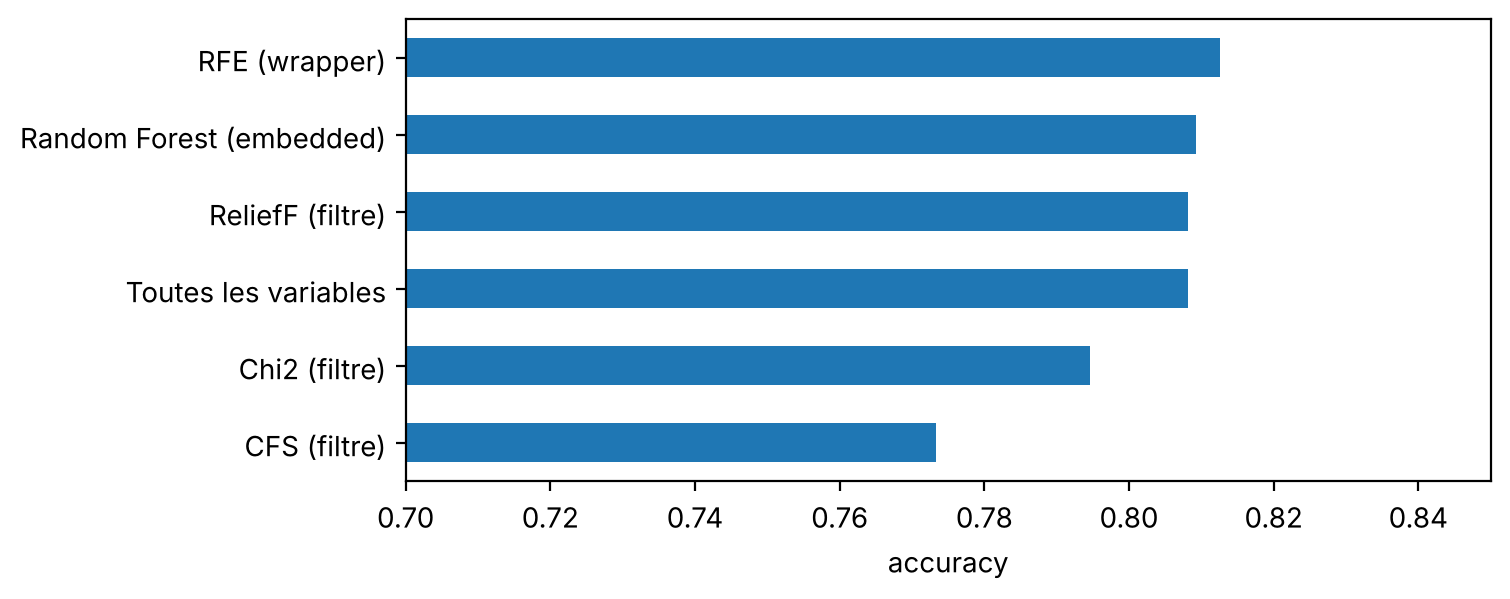

In [ ]:
methodes = {
    "Toutes les variables": list(X.columns),
    "Chi2 (filtre)": sel_chi2,
    "ReliefF (filtre)": sel_relief,
    "CFS (filtre)": sel_cfs,
    "RFE (wrapper)": sel_rfe,
    "Random Forest (embedded)": sel_rf,
}

modele = RandomForestClassifier(n_estimators=200, random_state=0)
accuracies = {}
for nom, liste in methodes.items():
    acc = cross_val_score(modele, X[liste], y, cv=5).mean()
    accuracies[nom] = acc
    print(nom, "-", len(liste), "variables - accuracy =", round(acc, 4))

pd.Series(accuracies).sort_values().plot(kind="barh", figsize=(7, 3))
plt.xlim(0.7, 0.85)
plt.xlabel("accuracy")
plt.show()

## 4. Réduction de dimensionnalité (PCA)

In [ ]:
X_std = StandardScaler().fit_transform(X)
pca = PCA().fit(X_std)
cumul = np.cumsum(pca.explained_variance_ratio_)
print("variance cumulée :", cumul.round(3))

n = int(np.argmax(cumul >= 0.95)) + 1
print("composantes pour 95% de variance :", n)

X_pca = PCA(n_components=n).fit_transform(X_std)
print("accuracy avec PCA :", round(cross_val_score(modele, X_pca, y, cv=5).mean(), 4))

variance cumulée : [0.26  0.471 0.663 0.767 0.856 0.925 0.976 1.   ]
composantes pour 95% de variance : 7


accuracy avec PCA : 0.7823
